# CSET485 Assignment 1 — Enrollment 2535
German Credit dataset | seed **535** | train/test **70/30**

In Colab, select **Runtime → Run all**. No separate dataset upload is needed. Internet is needed to read the UCI dataset. This notebook contains only the analysis; it does not generate a report.

**Target:** good credit = 1 (approval proxy), bad credit = 0. The original data does not record actual approvals. Here, positive means predicted approval.

**Preprocessing:** no missing values are expected (checked below). Unknown/no-account codes remain categories. Numeric features are scaled and categories are one-hot encoded using training data only. Outliers are counted but retained because they may be valid applicants.

Source: [UCI German Credit](https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data) and [codebook](https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.doc).

## 1. Load and check the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from IPython.display import display

SEED = 535
columns = ['checking','duration','history','purpose','amount','savings','employment',
           'installment','personal_status','guarantor','residence','property','age',
           'other_plans','housing','existing_credits','job','dependents','telephone','foreign_worker','class']
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data'
df = pd.read_csv(url, sep=r'\s+', names=columns)
y = (df['class'] == 1).astype(int)  # UCI good credit = approval proxy
X = df.drop(columns='class')
female = df.personal_status.isin(['A92','A95'])
num = ['duration','amount','installment','residence','age','existing_credits','dependents']
cat = [c for c in X if c not in num]
train, test = train_test_split(df.index, test_size=.30, random_state=SEED, stratify=y)
print('Rows:',len(df),'Missing:',int(df.isna().sum().sum()),'Train:',len(train),'Test:',len(test))
print('Target counts:',y.value_counts().to_dict())
# Outliers are flagged using training-only IQR fences, then retained.
q1,q3=X.loc[train,num].quantile(.25),X.loc[train,num].quantile(.75)
iqr=q3-q1
outlier_counts=((X[num]<q1-1.5*iqr)|(X[num]>q3+1.5*iqr)).sum()
print('Outlier counts (not removed):'); display(outlier_counts.to_frame('rows'))

Rows: 1000 Missing: 0 Train: 700 Test: 300
Target counts: {1: 700, 0: 300}
Outlier counts (not removed):


,rows
duration,70
amount,70
installment,0
residence,0
age,23
existing_credits,6
dependents,155


## 2. Part 1 — Compare OLS and logistic regression
Both models use the same training and test rows. The agreement matrix compares their decisions, rather than comparing predictions to actual labels.

In [2]:
prep = ColumnTransformer([('num',StandardScaler(),num),
                          ('cat',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False),cat)])
Ztrain = prep.fit_transform(X.loc[train])
Ztest = prep.transform(X.loc[test])
names = num + list(prep.named_transformers_['cat'].get_feature_names_out(cat))
ols = LinearRegression().fit(Ztrain,y.loc[train])
logit = LogisticRegression(C=1.0,solver='lbfgs',max_iter=5000,random_state=SEED).fit(Ztrain,y.loc[train])
linear = ols.predict(Ztest)
p = logit.predict_proba(Ztest)[:,1]
median = float(np.median(linear))
a,b = (linear>=median).astype(int),(p>=.5).astype(int)
agreement = confusion_matrix(a,b,labels=[0,1])
mismatch = int((a!=b).sum())
print('OLS median:',median,'OLS range:',linear.min(),linear.max())
print('Agreement matrix: rows OLS 0/1, columns logistic 0/1'); print(agreement)
print('Mismatch:',mismatch,100*mismatch/len(test),'percent')
print('Accuracy OLS:',accuracy_score(y.loc[test],a),'Logistic:',accuracy_score(y.loc[test],b))
print('Predicted positive OLS/logistic:',a.sum(),b.sum())
print('Logistic vs actual confusion matrix:'); print(confusion_matrix(y.loc[test],b))
coefs = pd.Series(logit.coef_[0],index=names)

OLS median: 0.7189263637761176 OLS range: -0.051324455457030696 1.564703937854182
Agreement matrix: rows OLS 0/1, columns logistic 0/1
[[ 69  81]
 [  0 150]]
Mismatch: 81 27.0 percent
Accuracy OLS: 0.6733333333333333 Logistic: 0.7566666666666667
Predicted positive OLS/logistic: 150 231
Logistic vs actual confusion matrix:
[[ 43  47]
 [ 26 184]]


## 3. Part 2.1 — Subgroup reversal
Compare the dependents coefficient overall, for female records, and for male records. This is a descriptive example selected during exploration. The same standard deviation is used in all three models. Check the confidence intervals before drawing conclusions: a sign reversal near zero is weak evidence.

Female = personal-status codes A92/A95; male = the other observed codes. This follows the dataset's limited historical encoding.

In [3]:
group_data = df.copy()
group_data['approval'] = y
group_data['gender'] = np.where(female, 'Female', 'Male')
group_data['dependents_z'] = (df.dependents - df.dependents.mean()) / df.dependents.std(ddof=0)

subgroup_rows = []
for name, data in [('All', group_data),
                   ('Female', group_data[female]),
                   ('Male', group_data[~female])]:
    model = smf.glm('approval ~ dependents_z', data=data,
                    family=sm.families.Binomial()).fit()
    low, high = model.conf_int().loc['dependents_z']
    subgroup_rows.append([name, len(data), model.params['dependents_z'], low, high])

subgroups = pd.DataFrame(subgroup_rows, columns=['Group', 'n', 'Coefficient', 'CI_low', 'CI_high'])
display(subgroups.round(6))
print('All intervals include zero: the reversal is small and uncertain.')
print('Good-credit rates by gender and dependents:')
display(group_data.groupby(['gender', 'dependents']).approval.agg(['count', 'mean']))
print('Gender composition within each dependents category:')
display(pd.crosstab(group_data.gender, df.dependents, normalize='columns').round(4))

,Group,n,Coefficient,CI_low,CI_high
0,All,1000,0.006596,-0.128999,0.142190
1,Female,310,-0.123149,-0.515882,0.269585
2,Male,690,-0.015537,-0.164386,0.133312


All intervals include zero: the reversal is small and uncertain.
Good-credit rates by gender and dependents:


count      mean
gender dependents                 
Female 1             296  0.652027
       2              14  0.571429
Male   1             549  0.724954
       2             141  0.716312

Gender composition within each dependents category:


dependents,1,2
gender,,
Female,0.3503,0.0903
Male,0.6497,0.9097


## 4. Part 2.2 — Remove checking-account status
Checking status is a plausible financial confounder. Keep the rows, scales and model settings fixed. Coefficient changes show sensitivity; they do not prove causation. Percentage change uses the absolute original coefficient.

In [4]:
# Keep exactly the same rows, scales, and L2 penalty.
keep=np.array([not n.startswith('checking_') for n in names])
reduced=LogisticRegression(C=1.0,solver='lbfgs',max_iter=5000,random_state=SEED).fit(Ztrain[:,keep],y.loc[train])
reduced_coef=pd.Series(reduced.coef_[0],index=np.array(names)[keep])
changes=pd.DataFrame({'full':coefs[keep],'reduced':reduced_coef})
changes['change']=changes.reduced-changes.full
changes['percent_change']=100*changes.change/changes.full.abs()
# Percent change uses absolute original value; positive = more positive coefficient.
changes['absolute_shift']=changes.change.abs()
changes=changes.sort_values('absolute_shift',ascending=False)
display(changes.head(4).round(6))
print('Largest absolute shift:', changes.index[0])

,full,reduced,change,percent_change,absolute_shift
savings_A63,0.074081,0.503446,0.429364,579.583875,0.429364
history_A34,1.263806,1.597052,0.333245,26.368397,0.333245
savings_A65,1.038880,1.341742,0.302861,29.152691,0.302861
history_A33,0.630477,0.910563,0.280086,44.424528,0.280086


Largest absolute shift: savings_A63


## 5. Part 2.3 — Confident mistakes
Extract all qualifying rows if fewer than 50 exist; otherwise sample 50 with seed 535. Compare their demographics with the test set. Short duration is a descriptive trait, not a proven cause of errors.

In [5]:
results=df.loc[test].copy(); results['row_id']=results.index+1
results['actual']=y.loc[test]; results['probability']=p
results['gender']=np.where(female.loc[test],'Female','Male')
wrong=results[((results.probability>=.75)&(results.actual==0))|((results.probability<=.25)&(results.actual==1))]
subset=wrong.sample(50,random_state=SEED) if len(wrong)>50 else wrong.copy()
subset.to_csv('adversarial_subset.csv', index=False)
display(subset[['row_id', 'age', 'gender', 'duration', 'actual', 'probability']])
print('High-confidence errors:',len(wrong),100*len(wrong)/len(test),'percent; selected:',len(subset))
summary=[]
for label,data in [('Test',results),('Subset',subset)]:
    summary.append({'sample':label,'n':len(data),'mean_age':data.age.mean(),'median_age':data.age.median(),
                    'min_age':data.age.min(),'max_age':data.age.max(),
                    'female_n':int((data.gender=='Female').sum()),'female_pct':100*(data.gender=='Female').mean(),
                    'under35_pct':100*(data.age<35).mean(),'age35_49_pct':100*data.age.between(35,49).mean(),
                    'age50plus_pct':100*(data.age>=50).mean(),
                    'amount_lt5000_pct':100*(data.amount<5000).mean(),
                    'duration_le24_pct':100*(data.duration<=24).mean()})
demographics=pd.DataFrame(summary); display(demographics.T)
print('Confident false positives:',int(((subset.probability>=.75)&(subset.actual==0)).sum()))
print('Relevant coefficients:',coefs[['amount','duration']].to_dict())

,row_id,age,gender,duration,actual,probability
331,332,30,Female,18,0,0.789983
351,352,29,Female,9,0,0.918535
349,350,32,Male,9,0,0.803469
395,396,32,Male,39,1,0.184497
188,189,20,Male,12,0,0.765225
647,648,26,Female,12,0,0.872991
457,458,35,Male,12,0,0.867006
278,279,32,Female,6,0,0.926941
80,81,44,Female,24,0,0.943920
598,599,31,Male,18,0,0.903574


High-confidence errors: 28 9.333333333333334 percent; selected: 28


,0,1
sample,Test,Subset
n,300,28
mean_age,35.103333,33.607143
median_age,32.0,30.0
min_age,20,20
max_age,74,61
female_n,90,9
female_pct,30.0,32.142857
under35_pct,55.333333,67.857143
age35_49_pct,32.666667,17.857143


Confident false positives: 22
Relevant coefficients: {'amount': -0.34881846681393236, 'duration': -0.3885481957347434}


## 6. Part 2.4 — Fairness metrics and trade-off
Group A = female; Group B = male. Sweep 0.05 to 0.95 in steps of 0.10. Use the assignment's formulas: DP = selection ratio; EO = minimum of TPR and FPR ratios; PP = precision ratio. Undefined ratios stay NaN.

The final comparison uses 0.85 → 0.45, where DP improves while EO worsens. Threshold choice is exploratory because this sweep uses the test set.

,threshold,DP,EO,PP,accuracy
0,0.05,1.0000,1.0000,0.8280,0.7000
1,0.15,0.9902,0.9699,0.8109,0.7067
2,0.25,0.9800,0.9641,0.8145,0.7133
3,0.35,0.9136,0.9036,0.8742,0.7567
4,0.45,0.8637,0.7857,0.9129,0.7667
5,0.55,0.8066,0.5893,0.9791,0.7333
6,0.65,0.8216,0.7202,0.9386,0.7067
7,0.75,0.7268,0.5893,0.9692,0.6867
8,0.85,0.7778,0.8698,0.9259,0.6067
9,0.95,0.4341,0.0000,1.0750,0.4500


,threshold,A_TPR,B_TPR,A_FPR,B_FPR,A_selection,B_selection
0,0.05,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,0.15,0.9636,0.9935,0.9714,0.9273,0.9667,0.9762
2,0.25,0.9455,0.9806,0.9143,0.8727,0.9333,0.9524
3,0.35,0.9273,0.9613,0.6571,0.7273,0.8222,0.9000
4,0.45,0.8909,0.9355,0.5143,0.6545,0.7444,0.8619
5,0.55,0.8000,0.8387,0.3429,0.5818,0.6222,0.7714
6,0.65,0.7091,0.7613,0.3143,0.4364,0.5556,0.6762
7,0.75,0.5818,0.6839,0.1714,0.2909,0.4222,0.5810
8,0.85,0.4545,0.5226,0.1429,0.1636,0.3333,0.4286
9,0.95,0.1455,0.2581,0.0000,0.0545,0.0889,0.2048


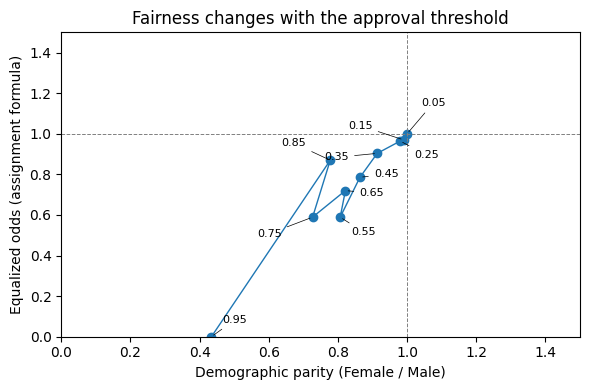

Threshold 0.85 → 0.45: DP 0.7778 → 0.8637 (11.05% gain)
EO 0.8698 → 0.7857 (9.67% loss)
Trade-off cost = 0.875
No tested threshold makes DP, EO and PP all equal to 1.


In [6]:
def ratio(a,b): return a/b if np.isfinite(a) and np.isfinite(b) and b!=0 else np.nan

def rates(mask,threshold):
    actual=y.loc[test].to_numpy()[mask]; pred=p[mask]>=threshold
    tp=int(((actual==1)&pred).sum()); fp=int(((actual==0)&pred).sum())
    fn=int(((actual==1)&~pred).sum()); tn=int(((actual==0)&~pred).sum())
    return {'selection':pred.mean(),'TPR':ratio(tp,tp+fn),'FPR':ratio(fp,fp+tn),'PPV':ratio(tp,tp+fp),
            'TP':tp,'FP':fp,'FN':fn,'TN':tn,'n':len(actual)}
mask=female.loc[test].to_numpy(); fair=[]
for t in np.round(np.arange(.05,1,.1),2):
    A,B=rates(mask,t),rates(~mask,t)
    tr,fr=ratio(A['TPR'],B['TPR']),ratio(A['FPR'],B['FPR'])
    eo=min(tr,fr) if np.isfinite(tr) and np.isfinite(fr) else np.nan
    fair.append({'threshold':t,'DP':ratio(A['selection'],B['selection']),'EO':eo,'PP':ratio(A['PPV'],B['PPV']),
                 'accuracy':accuracy_score(y.loc[test],p>=t),'TPR_ratio':tr,'FPR_ratio':fr,
                 **{f'A_{k}':v for k,v in A.items()},**{f'B_{k}':v for k,v in B.items()}})
fair=pd.DataFrame(fair); display(fair[['threshold','DP','EO','PP','accuracy']].round(4))
display(fair[['threshold', 'A_TPR', 'B_TPR', 'A_FPR', 'B_FPR', 'A_selection', 'B_selection']].round(4))
fig,ax=plt.subplots(figsize=(6,4))
ax.plot(fair.DP,fair.EO,'o-',lw=1)
for _,r in fair.iterrows():
    if np.isfinite(r.DP) and np.isfinite(r.EO): ax.annotate(f'{r.threshold:.2f}',(r.DP,r.EO),xytext={.05:(10,20),.15:(-40,8),.25:(10,-12),.35:(-38,-5),.45:(10,0),.55:(8,-13),.65:(10,-4),.75:(-40,-14),.85:(-35,10),.95:(8,10)}[r.threshold],textcoords='offset points',fontsize=8,arrowprops=dict(arrowstyle='-',lw=.5))
ax.axvline(1,color='gray',ls='--',lw=.7); ax.axhline(1,color='gray',ls='--',lw=.7)
ax.set(xlim=(0,1.5),ylim=(0,1.5),xlabel='Demographic parity (Female / Male)',ylabel='Equalized odds (assignment formula)',title='Fairness changes with the approval threshold')
fig.tight_layout(); plt.show()
# Relative percentage gain/loss, not percentage-point differences.
before = fair.loc[fair.threshold == .85].iloc[0]
after = fair.loc[fair.threshold == .45].iloc[0]
gain = 100 * (after.DP - before.DP) / before.DP
loss = 100 * (before.EO - after.EO) / before.EO
print(f'Threshold 0.85 → 0.45: DP {before.DP:.4f} → {after.DP:.4f} ({gain:.2f}% gain)')
print(f'EO {before.EO:.4f} → {after.EO:.4f} ({loss:.2f}% loss)')
print(f'Trade-off cost = {loss/gain:.3f}')
print('No tested threshold makes DP, EO and PP all equal to 1.')